In [ ]:
%pip install  pyheif
%pip install rawpy
import os
from google.colab import drive

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.3/5.3 MB 38.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 31.9 MB/s eta 0:00:00


In [ ]:
drive.mount('/content/drive')

# Ruta donde está almacenando el json con las credenciales de kaggle
kaggle_folder_path = "/content/drive/MyDrive/Kaggle"


if not os.path.exists(kaggle_folder_path):
    print(f"No se encontró la carpeta {kaggle_folder_path}")

os.environ['KAGGLE_CONFIG_DIR'] = kaggle_folder_path


if not os.path.exists("rostros-salon.zip"):
    print("Descargando dataset desde Kaggle...")
    try:
        !kaggle datasets download -d deliopalacios/rostros-salon
    except Exception as e:
        print("\n Error: No se encontró 'kaggle.json' o el token es inválido.")
        print(f"Asegúrate de subir kaggle.json a: {kaggle_folder_path}")
else:
    print("El zip del dataset ya está descargado.")


if not os.path.exists("rostros-salon"):
    print("Descomprimiendo el dataset...")
    !unzip -q rostros-salon.zip -d /content/rostros-salon


print("Estructura de directorios en /content/rostros-salon:")
!ls /content/rostros-salon

Mounted at /content/drive
Descargando dataset desde Kaggle...
Dataset URL: https://www.kaggle.com/datasets/deliopalacios/rostros-salon
License(s): unknown
100% 3.34G/3.34G [00:46<00:00, 77.0MB/s]

Descomprimiendo el dataset...
Estructura de directorios en /content/rostros-salon:
'ALEXANDER PEÑARANDA ARCE'	   'JOSHUA LATTKE CIFUENTES'
'ANA MARIA BAUTISTA RODRIGUEZ'	   'JUAN DIEGO ARISTIZABAL'
'BRIAN ANTONIO ANDRADE DIAZ'	   'KEVIN ALEXIS LÓPEZ CAMACHO'
'BYLEN YESID NASPIRAN REALPE'	   'KEVIN MANUEL GALLEGO APONZÁ'
'DANIEL FELIPE PATIÑO TRIVIÑO'	   'LUIS EDWAR MOSQUERA CONGO'
'DANIEL TORRES VALENCIA'	   'LUNA MARIA GAVIRIA ANDRADE'
'DANNA ANDREA RODRIGUEZ GALARCIO'  'NATALIA GIRALDO'
'DHENS BECERRA RESTREPO'	   'SEBASTIAN CARRERA MEDINA'
'IAN MARCO ARANGO VELEZ'	   'SOFIA VALENCIA SOLANO'
'JOHAN CAMILO BALANTA SANTACRUZ'   'VALENTINA SARRIA CARREÑO'
'JOSE ESTEBAN OTERO RADA'	   'VALERIE SOFIA OLAVE PINEDA'


In [ ]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split

In [ ]:
directorio_dataset = "/content/rostros-salon"
# Listar las subcarpetas (cada una es una clase)
class_names = sorted([d for d in os.listdir(directorio_dataset)
                      if os.path.isdir(os.path.join(directorio_dataset, d))])
num_clases = len(class_names)
print(f"Clases encontradas: {class_names}")
print(f"Total: {num_clases} clases")

# Crear diccionario para mapear nombre de clase -> entero
class_to_label = {name: i for i, name in enumerate(class_names)}

# Helper: queda solo el primer nombre
def primer_nombre(clase):
    return " ".join(clase.split()[0:2]).title()



Clases encontradas: ['ALEXANDER PEÑARANDA ARCE', 'ANA MARIA BAUTISTA RODRIGUEZ', 'BRIAN ANTONIO ANDRADE DIAZ', 'BYLEN YESID NASPIRAN REALPE', 'DANIEL FELIPE PATIÑO TRIVIÑO', 'DANIEL TORRES VALENCIA', 'DANNA ANDREA RODRIGUEZ GALARCIO', 'DHENS BECERRA RESTREPO', 'IAN MARCO ARANGO VELEZ', 'JOHAN CAMILO BALANTA SANTACRUZ', 'JOSE ESTEBAN OTERO RADA', 'JOSHUA LATTKE CIFUENTES', 'JUAN DIEGO ARISTIZABAL', 'KEVIN ALEXIS LÓPEZ CAMACHO', 'KEVIN MANUEL GALLEGO APONZÁ', 'LUIS EDWAR MOSQUERA CONGO', 'LUNA MARIA GAVIRIA ANDRADE', 'NATALIA GIRALDO', 'SEBASTIAN CARRERA MEDINA', 'SOFIA VALENCIA SOLANO', 'VALENTINA SARRIA CARREÑO', 'VALERIE SOFIA OLAVE PINEDA']
Total: 22 clases


In [ ]:
import pyheif
from PIL import Image

# La mayoria de imagenes de Esteban Otero estaban en .heic y daban problemas al momento de codificarlas
target_dir = "/content/rostros-salon/JOSE ESTEBAN OTERO RADA"

# Verificar que la carpeta existe
if not os.path.exists(target_dir):
    print(f"La carpeta no existe: {target_dir}")
else:
    # Listar todos los archivos .heic en esa carpeta (sin distinguir mayúsculas)
    heic_files = [f for f in os.listdir(target_dir) if f.lower().endswith('.heic')]

    print(f"Carpeta: {target_dir}")
    print(f"Archivos .HEIC encontrados: {len(heic_files)}")

    for heic_file in heic_files:
        heic_path = os.path.join(target_dir, heic_file)
        jpg_path = os.path.splitext(heic_path)[0] + '.jpg'

        try:
            heif_file = pyheif.read(heic_path)
            image = Image.frombytes(
                heif_file.mode,
                heif_file.size,
                heif_file.data,
                "raw",
                heif_file.mode,
                heif_file.stride,
            )
            image.save(jpg_path, "JPEG")
            os.remove(heic_path)  # Eliminar el original .heic
            print(f"Convertido: {heic_file} -> {os.path.basename(jpg_path)}")
        except Exception as e:
            print(f"Error con {heic_file}: {e}")

    print("Conversión completada")

Carpeta: /content/rostros-salon/JOSE ESTEBAN OTERO RADA
Archivos .HEIC encontrados: 91
Convertido: IMG_1364.HEIC -> IMG_1364.jpg
Convertido: IMG_1349.HEIC -> IMG_1349.jpg
Convertido: IMG_1493.HEIC -> IMG_1493.jpg
Convertido: IMG_1466.HEIC -> IMG_1466.jpg
Convertido: IMG_1347.HEIC -> IMG_1347.jpg
Convertido: IMG_1391.HEIC -> IMG_1391.jpg
Convertido: IMG_1485.HEIC -> IMG_1485.jpg
Convertido: IMG_1500.HEIC -> IMG_1500.jpg
Convertido: IMG_1330.HEIC -> IMG_1330.jpg
Convertido: IMG_1460.HEIC -> IMG_1460.jpg
Convertido: IMG_1435.HEIC -> IMG_1435.jpg
Convertido: IMG_1426.HEIC -> IMG_1426.jpg
Convertido: IMG_1456.HEIC -> IMG_1456.jpg
Convertido: IMG_1511.HEIC -> IMG_1511.jpg
Convertido: IMG_0671.HEIC -> IMG_0671.jpg
Convertido: IMG_1454.HEIC -> IMG_1454.jpg
Convertido: IMG_1464.HEIC -> IMG_1464.jpg
Convertido: IMG_1455.HEIC -> IMG_1455.jpg
Convertido: IMG_1484.HEIC -> IMG_1484.jpg
Convertido: IMG_1363.HEIC -> IMG_1363.jpg
Convertido: IMG_1492.HEIC -> IMG_1492.jpg
Convertido: IMG_1441.HEIC -> IM

In [ ]:
import tensorflow as tf
from PIL import Image, UnidentifiedImageError, ImageFile
import os

# Permite abrir imágenes truncadas en lugar de lanzar error
ImageFile.LOAD_TRUNCATED_IMAGES = True

EXTENSIONES = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}

reparadas = 0
eliminadas = 0

for root, dirs, files in os.walk(directorio_dataset):
    for filename in files:
        if os.path.splitext(filename)[1].lower() not in EXTENSIONES:
            continue

        filepath = os.path.join(root, filename)

        # 1. Si TF puede leerla, no tocar
        try:
            raw = tf.io.read_file(filepath)
            tf.io.decode_image(raw, channels=3, expand_animations=False)
            continue
        except Exception:
            pass

        # 2. TF falló → intentar reparar con Pillow
        try:
            with Image.open(filepath) as img:
                img.load()  # Con LOAD_TRUNCATED_IMAGES=True procesa lo que pueda
                img.convert('RGB').save(filepath, 'JPEG', quality=95)
            print(f"Reparada: {os.path.relpath(filepath, directorio_dataset)}")
            reparadas += 1
        except (UnidentifiedImageError, OSError, SyntaxError):
            # Corrupción total — Pillow tampoco puede abrirla
            os.remove(filepath)
            print(f" Eliminada: {os.path.relpath(filepath, directorio_dataset)}")
            eliminadas += 1

print(f"\nReparadas: {reparadas}  |  Eliminadas: {eliminadas}")

Reparada: ANA MARIA BAUTISTA RODRIGUEZ/Screenshot_2026-03-30-19-15-26-601_com.google.android.apps.photos-edit.jpg
Reparada: ANA MARIA BAUTISTA RODRIGUEZ/Screenshot_2026-03-30-19-14-56-695_com.google.android.apps.photos.jpg
Reparada: ANA MARIA BAUTISTA RODRIGUEZ/Screenshot_2026-03-30-19-08-55-885_com.google.android.apps.photos.jpg
Reparada: ANA MARIA BAUTISTA RODRIGUEZ/Screenshot_2026-03-30-19-10-08-320_com.google.android.apps.photos.jpg
Reparada: ANA MARIA BAUTISTA RODRIGUEZ/Screenshot_2026-03-30-19-17-06-688_com.google.android.apps.photos.jpg
Reparada: ANA MARIA BAUTISTA RODRIGUEZ/Screenshot_2026-03-30-19-08-01-619_com.google.android.apps.photos.jpg
Reparada: ANA MARIA BAUTISTA RODRIGUEZ/Screenshot_2026-03-26-09-34-55-811_com.whatsapp.jpg
Reparada: ANA MARIA BAUTISTA RODRIGUEZ/Screenshot_2026-03-26-09-39-39-752_com.whatsapp-edit.jpg
Reparada: ANA MARIA BAUTISTA RODRIGUEZ/Screenshot_2026-03-30-19-15-07-025_com.google.android.apps.photos.jpg
Reparada: ANA MARIA BAUTISTA RODRIGUEZ/Screen

In [ ]:
file_paths = []
labels = []

for class_name in class_names:
    class_dir = os.path.join(directorio_dataset, class_name)
    for img_file in os.listdir(class_dir):
        if img_file.lower().endswith(('.jpg', '.jpeg', '.png')):
            file_paths.append(os.path.join(class_dir, img_file))
            labels.append(class_to_label[class_name])

print(f"Total de imágenes encontradas: {len(file_paths)}")

Total de imágenes encontradas: 2140


In [ ]:
from collections import Counter
# --- 1. Conteo de imágenes por clase ---
conteos = {}
for class_name in class_names:
    class_dir = os.path.join(directorio_dataset, class_name)
    imagenes = [f for f in os.listdir(class_dir)
                if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp', '.webp'))]
    conteos[primer_nombre(class_name)] = len(imagenes)
total = sum(conteos.values())
promedio = total / len(conteos)
minimo = min(conteos.values())
maximo = max(conteos.values())
print(f"Tal imágenes:     {total}")
print(f"Clases:             {len(conteos)}")
print(f"Máx por clase:      {maximo}  ({max(conteos, key=conteos.get)})")
print(f"Mín por clase:      {minimo}  ({min(conteos, key=conteos.get)})")
print(f"Promedio por clase: {promedio:.1f}")
# Umbral de desbalance
UMBRAL_DESBALANCE = 2.0
if maximo / minimo > UMBRAL_DESBALANCE:
    print("\n ADVERTENCIA: Existe desbalance significativo entre clases.")
    print("   Considera usar class_weight en model.fit() para compensarlo.")
else:
    print("\nDataset relativamente balanceado.")

Tal imágenes:     2140
Clases:             22
Máx por clase:      108  (Sebastian Carrera)
Mín por clase:      72  (Dhens Becerra)
Promedio por clase: 97.3

Dataset relativamente balanceado.


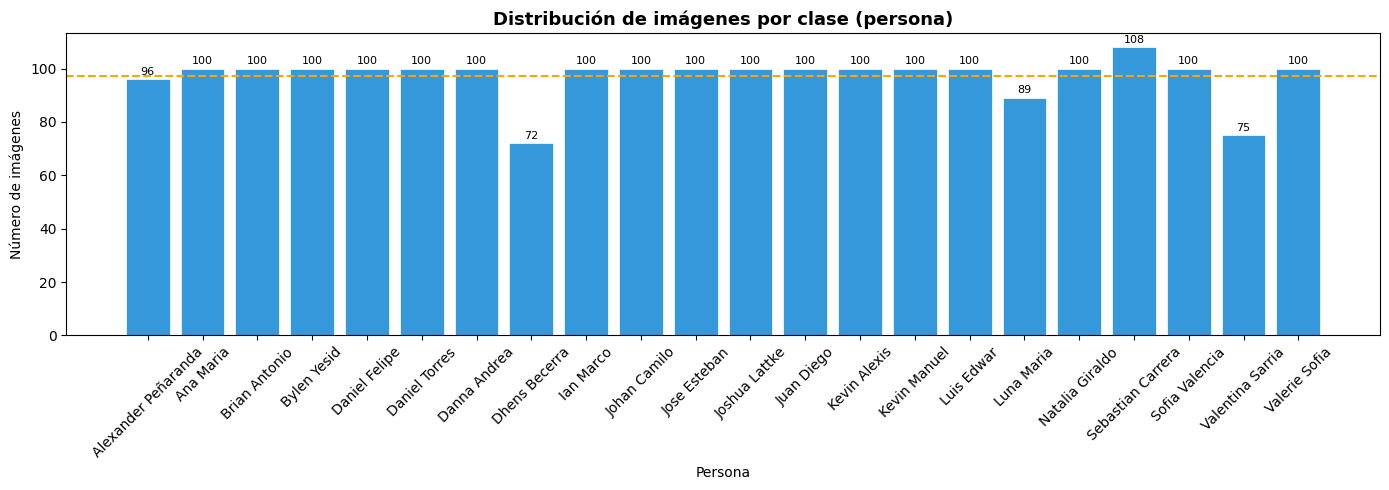

In [ ]:
import matplotlib.patches as mpatches
# --- 2. Gráfico de distribución de clases ---
nombres = list(conteos.keys())
valores = list(conteos.values())
# Colores: verde si está cerca del promedio, rojo si es muy bajo
colores = []
for v in valores:
    if v < promedio * 0.6:
        colores.append('#e74c3c')   # Rojo: muy pocas imágenes
    elif v > promedio * 1.4:
        colores.append('#27ae60')   # Verde: muchas imágenes
    else:
        colores.append('#3498db')   # Azul: normal
fig, ax = plt.subplots(figsize=(14, 5))
bars = ax.bar(nombres, valores, color=colores, edgecolor='white', linewidth=0.5)
ax.axhline(promedio, color='orange', linestyle='--', linewidth=1.5,
           label=f'Promedio ({promedio:.0f})')
ax.set_xlabel("Persona")
ax.set_ylabel("Número de imágenes")
ax.set_title("Distribución de imágenes por clase (persona)", fontsize=13, fontweight='bold')
ax.tick_params(axis='x', rotation=45)
# Agregar etiquetas encima de cada barra
for bar, val in zip(bars, valores):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
            str(val), ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.show()

In [ ]:
IMG_SIZE = (96, 96)   # Tamaño al que redimensionaremos las imágenes
BATCH_SIZE = 16
SEED = 5

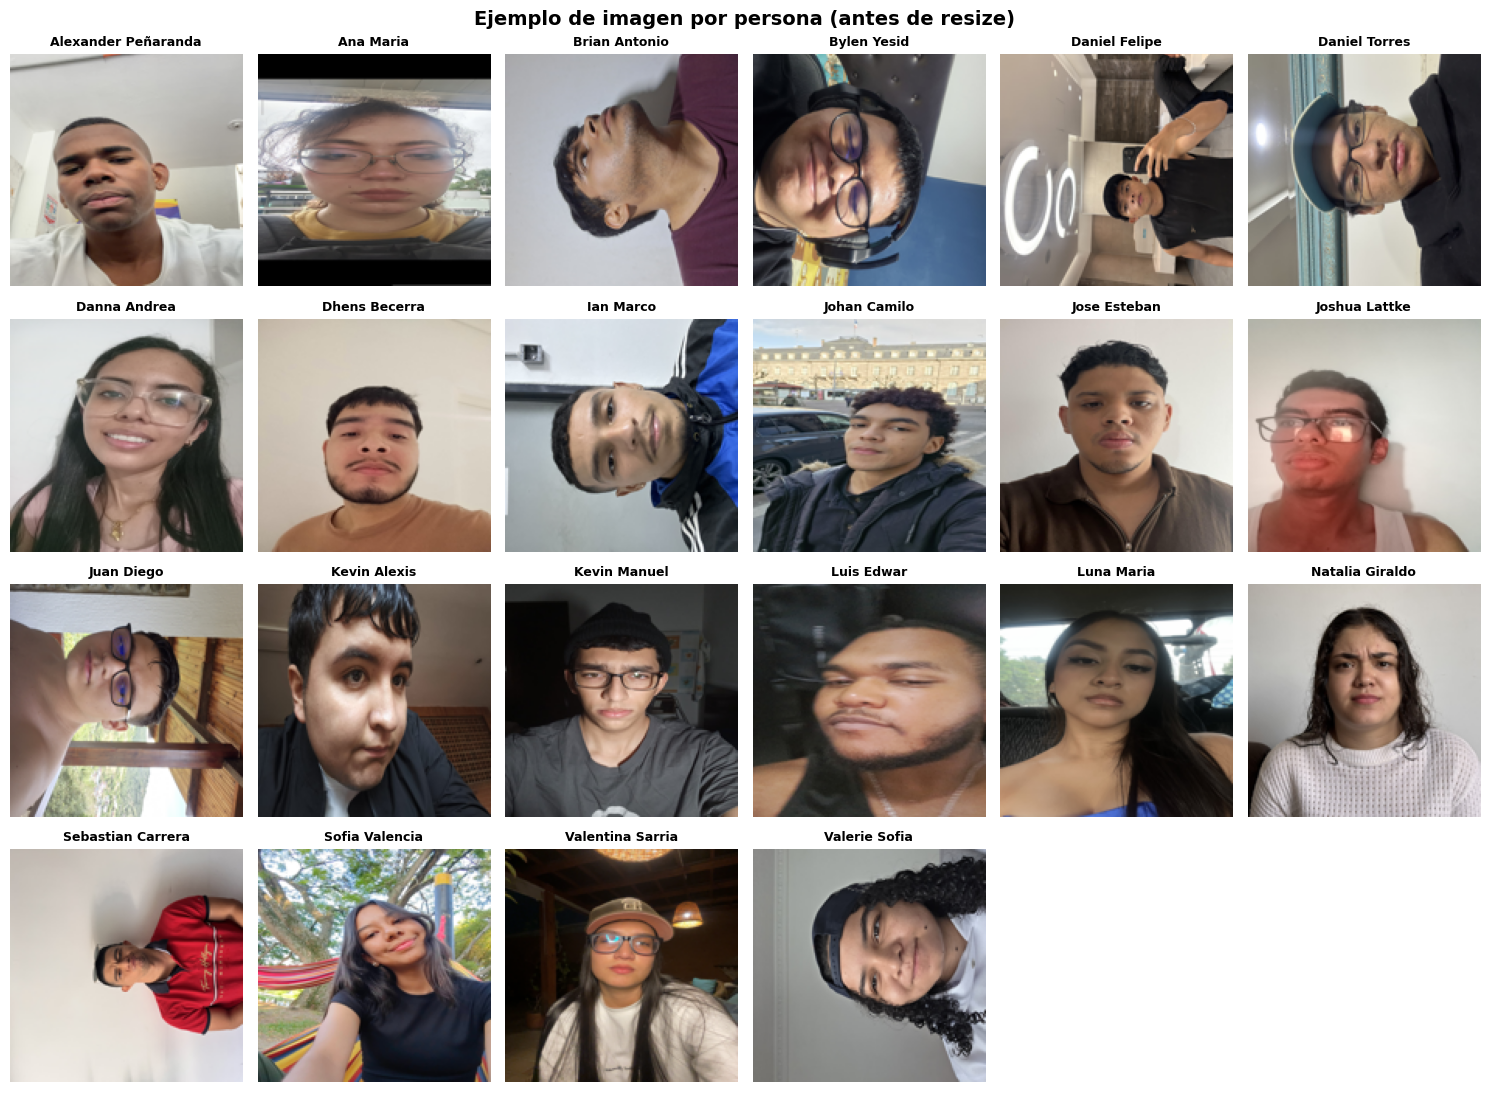

In [ ]:
# --- 4. Muestra visual: una imagen por persona ---
import random
random.seed(SEED)

n_cols = 6
n_rows = (len(class_names) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 2.5, n_rows * 2.8))
axes = axes.flatten()

for idx, class_name in enumerate(class_names):
    class_dir = os.path.join(directorio_dataset, class_name)
    archivos = [f for f in os.listdir(class_dir)
                if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
    if not archivos:
        axes[idx].axis('off')
        continue

    img_path = os.path.join(class_dir, random.choice(archivos))
    try:
        img = Image.open(img_path).convert('RGB')
        img = img.resize((150, 150))
        axes[idx].imshow(img)
        axes[idx].set_title(primer_nombre(class_name), fontsize=9, fontweight='bold')
    except Exception:
        axes[idx].set_title(f"Error\n{primer_nombre(class_name)}", fontsize=8)
    axes[idx].axis('off')

# Ocultar ejes sobrantes
for ax in axes[len(class_names):]:
    ax.axis('off')

plt.suptitle("Ejemplo de imagen por persona (antes de resize)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


In [ ]:
# # --- 5. Estadísticas de color/brillo por clase ---
# # (muestra con max 5 imágenes por clase para no tardar demasiado)
# MAX_POR_CLASE = 5
# brillos_por_clase = {}

# for class_name in class_names:
#     class_dir = os.path.join(directorio_dataset, class_name)
#     archivos = [f for f in os.listdir(class_dir)
#                 if f.lower().endswith(('.jpg', '.jpeg', '.png'))][:MAX_POR_CLASE]
#     brillos = []
#     for fname in archivos:
#         try:
#             img = Image.open(os.path.join(class_dir, fname)).convert('L')  # escala de grises
#             arr = np.array(img, dtype=np.float32) / 255.0
#             brillos.append(arr.mean())
#         except Exception:
#             pass
#     if brillos:
#         brillos_por_clase[primer_nombre(class_name)] = np.mean(brillos)

# nombres_b = list(brillos_por_clase.keys())
# valores_b = list(brillos_por_clase.values())

# fig, ax = plt.subplots(figsize=(14, 4))
# colores_b = ['#f39c12' if v < 0.3 else '#2ecc71' if v > 0.6 else '#3498db' for v in valores_b]
# ax.bar(nombres_b, valores_b, color=colores_b, edgecolor='white')
# ax.axhline(np.mean(valores_b), color='red', linestyle='--',
#            label=f'Brillo promedio global ({np.mean(valores_b):.2f})')
# ax.set_ylim(0, 1)
# ax.set_ylabel("Brillo promedio (0=oscuro, 1=claro)")
# ax.set_title("Brillo promedio por persona", fontsize=13, fontweight='bold')
# ax.tick_params(axis='x', rotation=45)
# ax.legend()
# plt.tight_layout()
# plt.show()

# print("\n💡 Clases con bajo brillo podrían tener fotos en ambientes oscuros.")
# print("   Las augmentaciones de brillo/contraste ya en el modelo ayudan con esto.")


In [ ]:
# ----------------------------------------------
# 2. DIVIDIR EN TRAIN, VAL Y TEST (estratificado)
# ----------------------------------------------
# Primero separamos test (20%)
train_val_paths, test_paths, train_val_labels, test_labels = train_test_split(
    file_paths, labels, test_size=0.2, random_state=SEED, stratify=labels
)

# Luego separamos train (80% del resto -> 64% total) y val (16% total)
train_paths, val_paths, train_labels, val_labels = train_test_split(
    train_val_paths, train_val_labels, test_size=0.2, random_state=SEED, stratify=train_val_labels
)

print(f"Train: {len(train_paths)} imágenes")
print(f"Val: {len(val_paths)} imágenes")
print(f"Test: {len(test_paths)} imágenes")

Train: 1369 imágenes
Val: 343 imágenes
Test: 428 imágenes


In [ ]:
# ----------------------------------------------
# 3. CREAR PIPELINE DE DATOS (carga diferida)
# ----------------------------------------------
def load_and_preprocess(file_path, label):
    raw = tf.io.read_file(file_path)
    image = tf.image.decode_image(raw, channels=3)
    image.set_shape([None, None, 3])  # shape dinámico
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

def augmentar(imagen, etiqueta):
    imagen = tf.image.random_flip_left_right(imagen)
    imagen = tf.image.random_brightness(imagen, 0.25)
    imagen = tf.image.random_contrast(imagen, 0.7, 1.3)
    imagen = tf.image.random_saturation(imagen, 0.7, 1.3)
    imagen = tf.image.random_hue(imagen, 0.05)
    return imagen, etiqueta

AUTOTUNE = tf.data.AUTOTUNE

# Split 70 / 15 / 15
X_tmp, X_test, y_tmp, y_test = train_test_split(
    file_paths, labels, test_size=0.15, stratify=labels, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(
    X_tmp, y_tmp, test_size=0.176, stratify=y_tmp, random_state=SEED)

print(f'Train: {len(X_train)} | Val: {len(X_val)} | Test: {len(X_test)}')

# ── Construir tf.data pipelines ────────────────────────────────────────────────
def make_dataset(paths, etiquetas, augment=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, etiquetas))
    ds = ds.map(load_and_preprocess, num_parallel_calls=tf.data.AUTOTUNE)
    if augment:
        ds = ds.map(augmentar, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.shuffle(500, seed=SEED).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
    return ds

ds_train = make_dataset(X_train, y_train, augment=True)
ds_val   = make_dataset(X_val,   y_val,   augment=False)
ds_test  = make_dataset(X_test,  y_test,  augment=False)
print('Datasets creados correctamente')

Train: 1498 | Val: 321 | Test: 321
Datasets creados correctamente


In [ ]:
from tensorflow.keras import layers, models, optimizers, backend as K
from tensorflow.keras.regularizers import l2
from tensorflow import keras

def crear_cnn(num_clases):
    """
    CNN secuencial diseñada desde cero para clasificación de rostros.
    4 bloques convolucionales progresivos (32→64→128→256 filtros).
    Sin Transfer Learning — arquitectura original completamente manual.
    ~1.2M parámetros (apropiado para ~1000 imágenes).
    """
    modelo = keras.Sequential([
        keras.Input(shape=(IMG_SIZE[0],IMG_SIZE[1],3)),

        # ── Bloque 1: extracción de bordes básicos ──────────────────────────
        layers.Conv2D(32, 3, padding='same', use_bias=False),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.Conv2D(32, 3, padding='same', use_bias=False),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.MaxPooling2D(2),          # 96→48
        layers.Dropout(0.15),

        # ── Bloque 2: texturas ───────────────────────────────────────────────
        layers.Conv2D(64, 3, padding='same', use_bias=False),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.Conv2D(64, 3, padding='same', use_bias=False),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.MaxPooling2D(2),          # 48→24
        layers.Dropout(0.20),

        # ── Bloque 3: patrones de nivel medio ───────────────────────────────
        layers.Conv2D(128, 3, padding='same', use_bias=False),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.Conv2D(128, 3, padding='same', use_bias=False),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.MaxPooling2D(2),          # 24→12
        layers.Dropout(0.25),

        # ── Bloque 4: características faciales de alto nivel ─────────────────
        layers.Conv2D(256, 3, padding='same', use_bias=False),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.MaxPooling2D(2),          # 12→6
        layers.Dropout(0.25),

        # ── Clasificador ─────────────────────────────────────────────────────
        layers.GlobalAveragePooling2D(),
        layers.Dense(256, use_bias=False),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.Dropout(0.5),
        layers.Dense(num_clases, activation='softmax')
    ], name='CNN_Rostros')
    return modelo


modelo = crear_cnn(len(class_names))

modelo.compile(
    optimizer=keras.optimizers.Adam(learning_rate=3e-4),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

modelo.summary()


Model: "CNN_Rostros"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 96, 96, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 96, 96, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 96, 96, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 96, 96, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 96, 96, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 96, 96, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 48, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 48, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 48, 48, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 48, 48, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 48, 48, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 48, 48, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 48, 48, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 48, 48, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 24, 24, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 24, 24, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 24, 24, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 24, 24, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 24, 24, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 24, 24, 128)    │             

 Total params: 656,502 (2.50 MB)

 Trainable params: 654,582 (2.50 MB)

 Non-trainable params: 1,920 (7.50 KB)

In [ ]:
from tensorflow.keras.callbacks import (EarlyStopping, ModelCheckpoint,
                                         ReduceLROnPlateau)
from sklearn.utils.class_weight import compute_class_weight

NUM_CLASES = len(class_names)
pesos = compute_class_weight(
    class_weight='balanced',
    classes=np.arange(NUM_CLASES),
    y=y_train
)
class_weights = dict(enumerate(pesos))
print('Pesos de clase calculados ')
print({k: f'{v:.2f}' for k, v in class_weights.items()})

# ── Callbacks ──────────────────────────────────────────────────────────────────
early_stop = EarlyStopping(
    monitor='val_accuracy',
    patience=15,
    restore_best_weights=True,
    verbose=1,
    start_from_epoch=20    # dar tiempo al modelo para arrancar
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=6,
    min_lr=5e-7,
    verbose=1
)

checkpoint = ModelCheckpoint(
    filepath='/content/drive/MyDrive/cnn_rostros_best.keras',
    monitor='val_accuracy',
    save_best_only=True,
    verbose=1
)

# ── Entrenamiento ──────────────────────────────────────────────────────────────
historial = modelo.fit(
    ds_train,
    validation_data=ds_val,
    epochs=100,
    callbacks=[early_stop, reduce_lr, checkpoint],
    class_weight=class_weights
)


Pesos de clase calculados 
{0: '1.02', 1: '0.97', 2: '0.97', 3: '0.97', 4: '0.97', 5: '0.97', 6: '0.97', 7: '1.36', 8: '0.97', 9: '0.97', 10: '0.97', 11: '0.97', 12: '0.97', 13: '0.97', 14: '0.97', 15: '0.97', 16: '1.10', 17: '0.97', 18: '0.90', 19: '0.97', 20: '1.28', 21: '0.97'}
Epoch 1/80
94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.0901 - loss: 3.4077
Epoch 1: val_accuracy improved from None to 0.04673, saving model to /content/drive/MyDrive/cnn_rostros_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/cnn_rostros_best.keras
94/94 ━━━━━━━━━━━━━━━━━━━━ 203s 2s/step - accuracy: 0.1068 - loss: 3.3258 - val_accuracy: 0.0467 - val_loss: 3.2649 - learning_rate: 3.0000e-04
Epoch 2/80
94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.1785 - loss: 2.9086
Epoch 2: val_accuracy did not improve from 0.04673
94/94 ━━━━━━━━━━━━━━━━━━━━ 196s 2s/step - accuracy: 0.1862 - loss: 2.9038 - val_accuracy: 0.0467 - val_loss: 3.9615 - learning_rate: 3.0000e-04
Epoch 3/80
94/94 

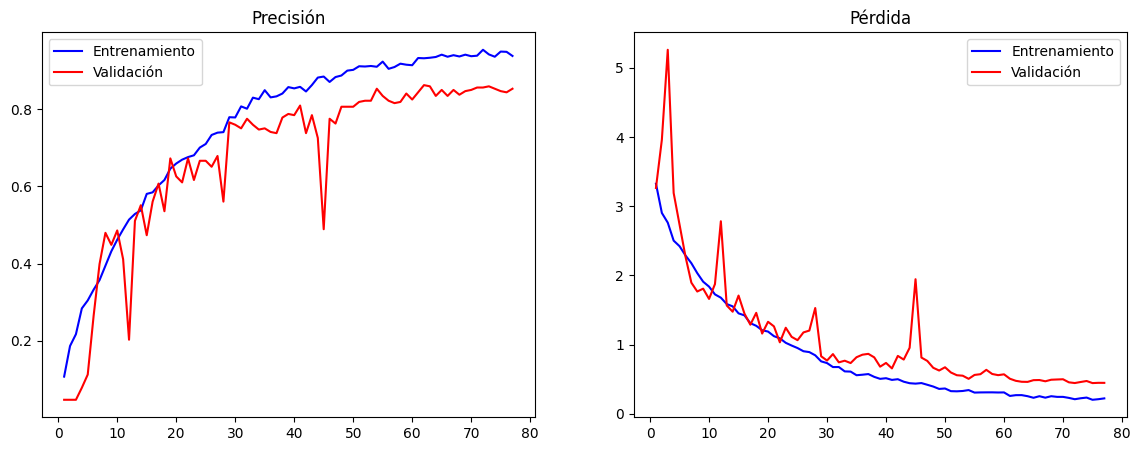

In [ ]:
def graficar_historial(hist):
    acc = hist.history['accuracy']
    val_acc = hist.history['val_accuracy']
    loss = hist.history['loss']
    val_loss = hist.history['val_loss']
    epochs = range(1, len(acc)+1)
    plt.figure(figsize=(14,5))
    plt.subplot(1,2,1)
    plt.plot(epochs, acc, 'b-', label='Entrenamiento')
    plt.plot(epochs, val_acc, 'r-', label='Validación')
    plt.title('Precisión')
    plt.legend()
    plt.subplot(1,2,2)
    plt.plot(epochs, loss, 'b-', label='Entrenamiento')
    plt.plot(epochs, val_loss, 'r-', label='Validación')
    plt.title('Pérdida')
    plt.legend()
    plt.show()

graficar_historial(historial)


Precisión en test: 85.05%
                     precision    recall  f1-score   support

Alexander Peñaranda       1.00      1.00      1.00        15
          Ana Maria       0.85      0.73      0.79        15
      Brian Antonio       1.00      1.00      1.00        15
        Bylen Yesid       0.82      0.93      0.88        15
      Daniel Felipe       0.81      0.87      0.84        15
      Daniel Torres       0.83      1.00      0.91        15
       Danna Andrea       0.83      1.00      0.91        15
      Dhens Becerra       0.92      1.00      0.96        11
          Ian Marco       1.00      0.67      0.80        15
       Johan Camilo       0.77      0.67      0.71        15
       Jose Esteban       0.93      0.87      0.90        15
      Joshua Lattke       0.79      1.00      0.88        15
         Juan Diego       0.64      0.47      0.54        15
       Kevin Alexis       0.61      0.73      0.67        15
       Kevin Manuel       0.87      0.87      0.87        

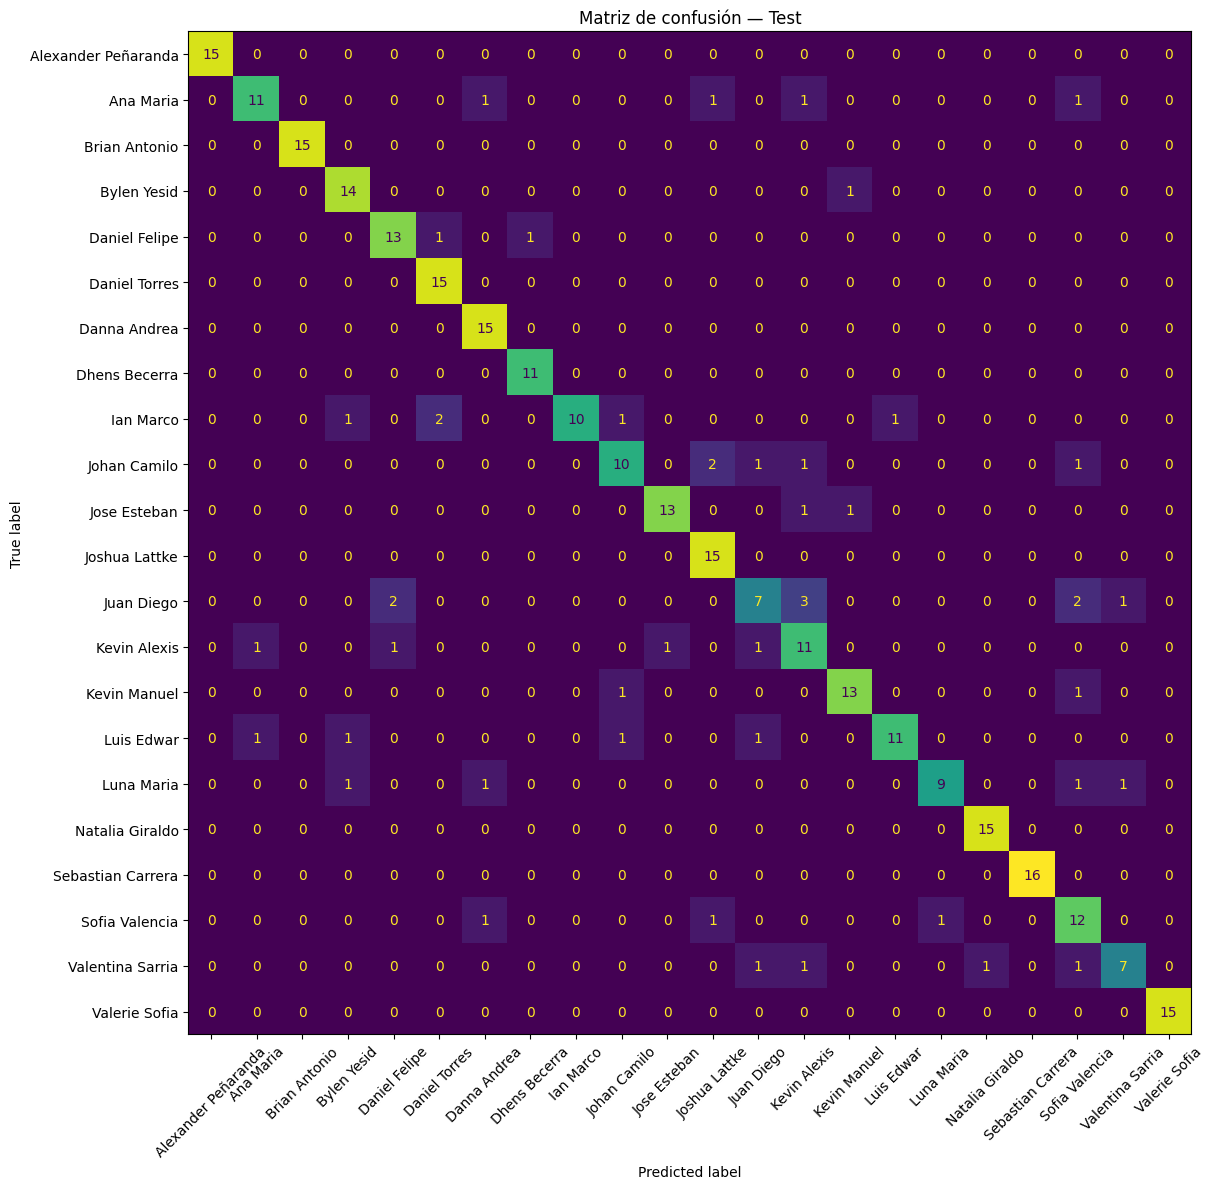

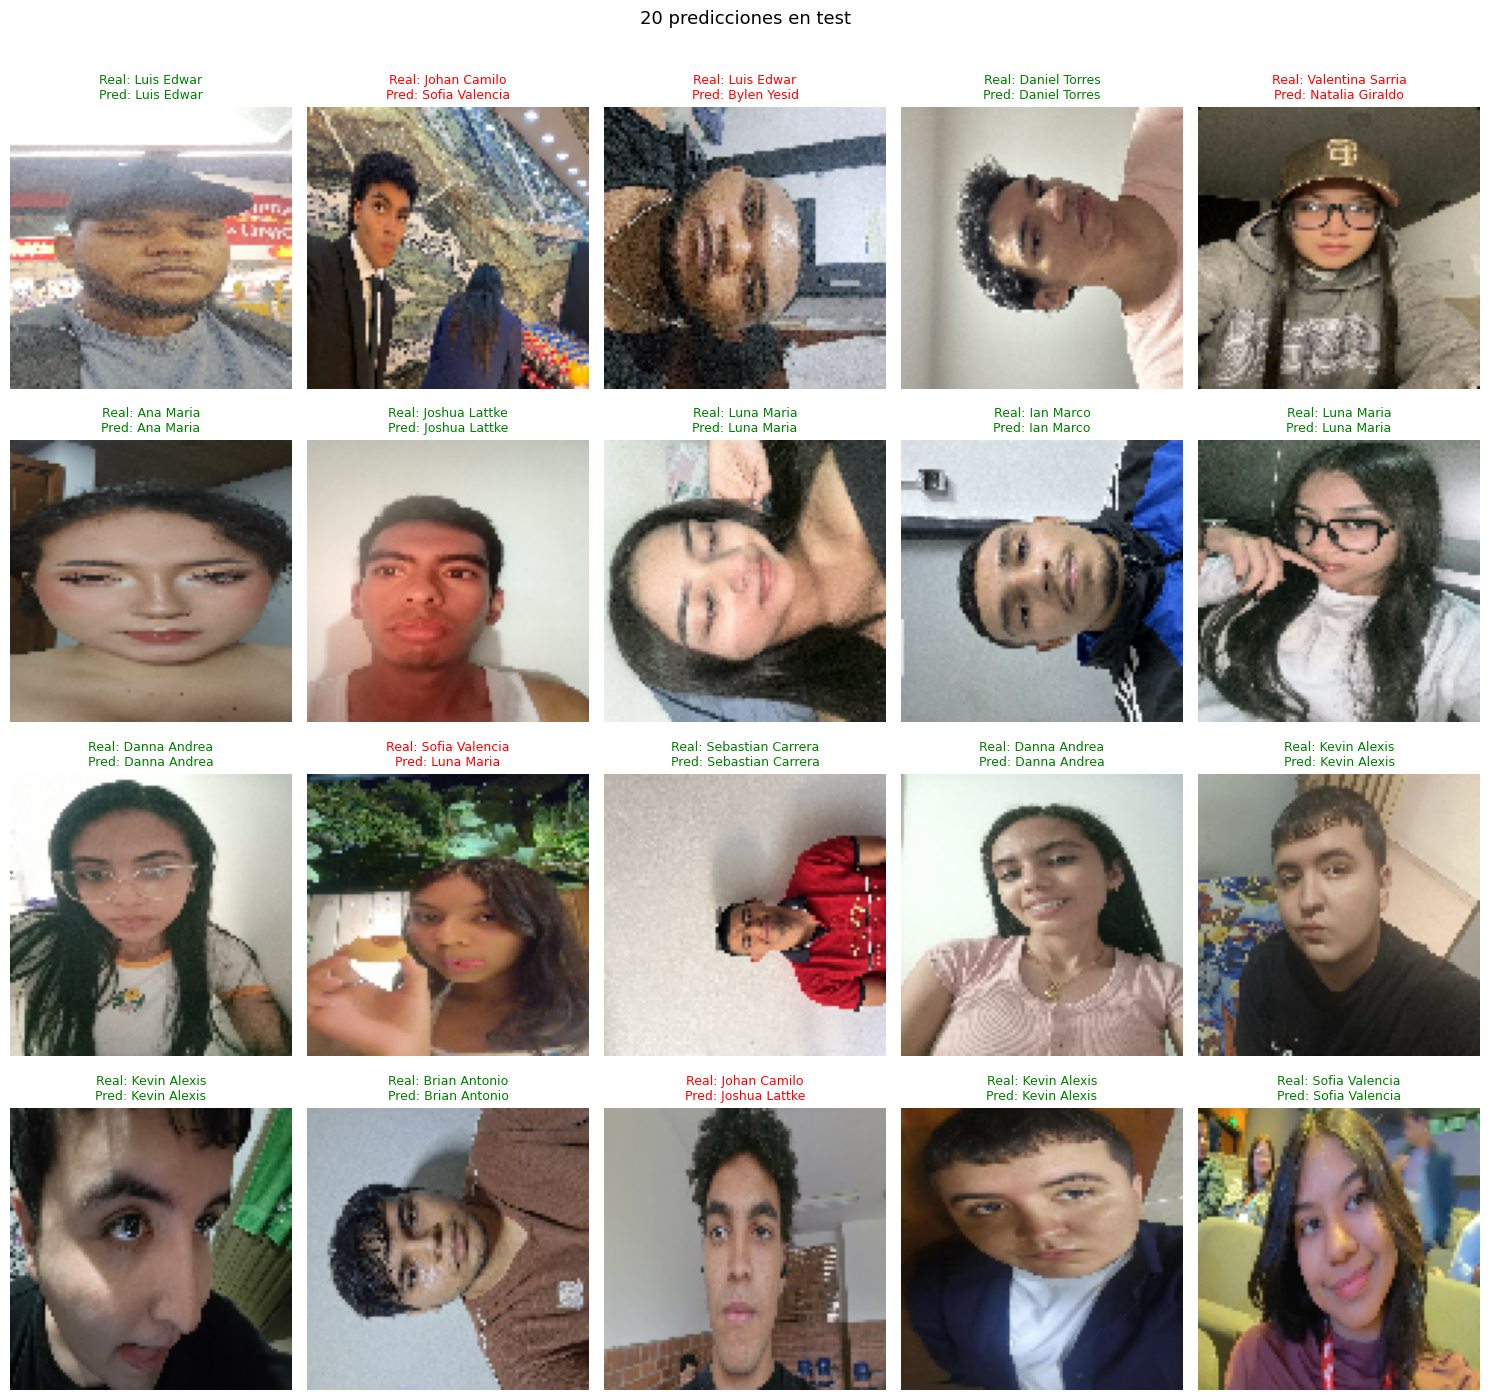

In [ ]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, confusion_matrix
import numpy as np

# Evaluar en test
test_loss, test_acc = modelo.evaluate(ds_test, verbose=0)
print(f"Precisión en test: {test_acc*100:.2f}%")

# --- Recoger TODAS las predicciones del test para métricas y imágenes para visualización ---
all_images_for_vis = []
all_true_labels = []
all_predicted_labels = []

# Define NUM_MUESTRAS here to ensure consistency
NUM_MUESTRAS_VIS = 20

for imgs, lbls in ds_test:
    preds = modelo.predict(imgs, verbose=0)
    all_true_labels.extend(lbls.numpy())
    all_predicted_labels.extend(np.argmax(preds, axis=1))

    # Collect images for visualization only up to NUM_MUESTRAS_VIS
    if len(all_images_for_vis) < NUM_MUESTRAS_VIS:
        for img_tensor in imgs.numpy():
            if len(all_images_for_vis) < NUM_MUESTRAS_VIS:
                all_images_for_vis.append(img_tensor)
            else:
                break # Stop collecting images once NUM_MUESTRAS_VIS is reached

y_real = np.array(all_true_labels)
y_pred = np.array(all_predicted_labels)

nombres_cortos = [primer_nombre(c) for c in class_names]

# --- Reporte de clasificación ---
print(classification_report(y_real, y_pred, target_names=nombres_cortos))

# --- Matriz de confusión ---
cm = confusion_matrix(y_real, y_pred)
fig, ax = plt.subplots(figsize=(14, 12))
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=nombres_cortos).plot(
    ax=ax, colorbar=False, xticks_rotation=45
)
plt.title("Matriz de confusión — Test")
plt.tight_layout()
plt.show()

# --- Visualizar 20 predicciones ---
COLS = 5
ROWS = NUM_MUESTRAS_VIS // COLS

fig, axes = plt.subplots(ROWS, COLS, figsize=(COLS * 3, ROWS * 3.5))
axes = axes.flatten()

# Use the already collected data for visualization
for i in range(NUM_MUESTRAS_VIS):
    ax = axes[i]
    ax.imshow((all_images_for_vis[i] * 255).astype("uint8"))
    ax.axis("off")

    real = primer_nombre(class_names[all_true_labels[i]])
    pred = primer_nombre(class_names[all_predicted_labels[i]])
    correcto = real == pred

    ax.set_title(
        f"Real: {real}\nPred: {pred}",
        fontsize=9,
        color="green" if correcto else "red"
    )

plt.suptitle("20 predicciones en test", fontsize=13, y=1.01)
plt.tight_layout()
plt.show()